<a href="https://colab.research.google.com/github/flango2023/Pulso_F4/blob/main/03_prototipo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pulso Fase 4 - Notebook 3: Protótipo do Assistente Cardiológico Virtual
Autor: Richard Schmitz | RM 567951 | Turma 2TIAOR-2026
Projeto: Pulso, Inteligência Cardiológica com Consciência de Dados (CardioIA, FIAP)
## Objetivo
Apresentar o modelo treinado no Notebook 2 (ResNet50 com Transfer Learning) em uma interface simples dentro do notebook: o usuário escolhe uma radiografia de exemplo do conjunto de teste ou envia uma imagem, e o protótipo mostra a pontuação do modelo, se a imagem foi sinalizada para revisão e quais regiões mais pesaram no resultado (Grad-CAM).
## Decisões e justificativas
| Decisão | Escolha | Por quê |
|---|---|---|
| Modelo | ResNet50 do Notebook 2, com o limiar escolhido na validação | Teve a maior AUC-ROC no teste. A vantagem sobre a CNN do zero é uma hipótese, não está demonstrada em todas as métricas |
| Linguagem do resultado | "Pontuação" e "sinalizada para revisão", nunca "diagnóstico" ou "probabilidade" | O modelo foi treinado com peso de classe e não é calibrado. A pontuação não é um risco em porcentagem |
| Contexto exibido | Recall, precisão e falsos positivos do teste, lidos do `metricas_nb2.json` | O usuário precisa ver que a maioria das sinalizações não tem cardiomegalia no laudo |
| Pré-processamento | Mesma função do Notebook 1 (cinza, 224 x 224, LANCZOS, uint8) | Entradas diferentes das do treino mudam o resultado. Uma célula de verificação confere isso |
| Interpretabilidade | Grad-CAM na última camada convolucional | Mostra onde o modelo "olhou". É um mapa de atenção do modelo, não uma localização anatômica validada |
| Privacidade | Imagens enviadas ficam só na memória da sessão | Nada é gravado em disco ou no repositório |
## Aviso
Projeto acadêmico. Nada aqui produz diagnóstico nem deve apoiar decisão clínica.

In [1]:
import io
import os
import sys
import json
import shutil
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import roc_auc_score
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
except ImportError:
    widgets = None
    display = print
warnings.filterwarnings("ignore")

SEED = 42
TAMANHO = 224
try:
    import google.colab  # noqa: F401
    COLAB = True
except ImportError:
    COLAB = False
print("Ambiente:", "Google Colab" if COLAB else "Local")
print("TensorFlow:", tf.__version__, "| ipywidgets:", widgets.__version__ if widgets else "nao instalado")

Ambiente: Google Colab
TensorFlow: 2.21.0 | ipywidgets: 7.7.1


## 1. Pastas, modelo e parâmetros do protótipo
O notebook usa os arquivos gerados nos Notebooks 1 e 2, guardados no Drive: o modelo `modelo_resnet50.keras`, o `metricas_nb2.json` (limiar e métricas do teste) e as previsões do teste. As radiografias de exemplo vêm da pasta do dataset baixado no Notebook 1.

In [2]:
BASE = Path("/content/pulso_f4") if COLAB else Path("./pulso_f4")
if COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = Path("/content/drive/MyDrive/Pulso_F4")
    except Exception as erro:
        print("Drive nao montado, usando o disco temporario:", erro)
SAIDA = BASE / "saida"
DATA = BASE / "data"
necessarios = ["modelo_resnet50.keras", "metricas_nb2.json", "pred_teste_resnet50.csv", "teste.npz"]
faltando = [n for n in necessarios if not (SAIDA / n).exists()]
if faltando:
    raise FileNotFoundError("Arquivos nao encontrados em %s: %s. Execute os Notebooks 1 e 2 antes." % (SAIDA, faltando))

modelo = keras.models.load_model(SAIDA / "modelo_resnet50.keras")
metricas = json.loads((SAIDA / "metricas_nb2.json").read_text(encoding="utf-8"))
LIMIAR = float(metricas["modelos"]["resnet50"]["limiar"])
TESTE = metricas["modelos"]["resnet50"]["teste"]
print("Modelo carregado:", modelo.name, "| parametros:", modelo.count_params())
print("Limiar (escolhido na validacao): %.2f" % LIMIAR)

IMAGENS = {p.name: p for p in DATA.rglob("*") if p.suffix.lower() in {".png", ".jpg", ".jpeg"}} if DATA.exists() else {}
print("Radiografias de exemplo disponiveis:", len(IMAGENS))
if not IMAGENS:
    print("ATENCAO: dataset nao encontrado em", DATA, "- a galeria de exemplos fica indisponivel. O envio de imagens continua funcionando.")

Mounted at /content/drive
Modelo carregado: resnet50_transfer | parametros: 23589761
Limiar (escolhido na validacao): 0.35
Radiografias de exemplo disponiveis: 5606


## 2. Pré-processamento, previsão e Grad-CAM
`preparar` repete o pré-processamento do Notebook 1. A normalização da ResNet50 (replicar o canal e subtrair a média da ImageNet) já está dentro do modelo.

O Grad-CAM usa o gradiente da saída em relação à última camada convolucional (`conv5_block3_out`) para pesar cada mapa de ativação. O resultado é um mapa de 7 x 7 ampliado para 224 x 224. Ele indica o que influenciou a pontuação, **não** onde está uma lesão.

In [3]:
def preparar(imagem):
    """Mesmo pre-processamento do Notebook 1: cinza, 224 x 224 (LANCZOS), uint8."""
    imagem = imagem.convert("L").resize((TAMANHO, TAMANHO), Image.Resampling.LANCZOS)
    return np.asarray(imagem, dtype=np.uint8)

# Partes do modelo usadas no Grad-CAM (o aumento de dados nao atua na inferencia)
base_resnet = modelo.get_layer("resnet50")
pre = keras.Model(modelo.input, modelo.get_layer("media_imagenet").output)
conv = keras.Model(base_resnet.input, base_resnet.get_layer("conv5_block3_out").output)
gap = next(c for c in modelo.layers if isinstance(c, layers.GlobalAveragePooling2D))
saida_modelo = modelo.get_layer("cardiomegalia")

def pontuar_com_gradcam(x):
    """x: (1, 224, 224, 1) float32 com valores 0-255. Devolve (pontuacao, mapa 7x7 normalizado)."""
    entrada = pre(x, training=False)
    with tf.GradientTape() as fita:
        mapas = conv(entrada, training=False)
        fita.watch(mapas)
        pontuacao = saida_modelo(gap(mapas))
    grad = fita.gradient(pontuacao, mapas)
    pesos = tf.reduce_mean(grad, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(pesos * mapas, axis=-1))[0].numpy()
    if cam.max() > 0:
        cam = cam / cam.max()
    return float(pontuacao.numpy()[0, 0]), cam

def contexto_do_teste():
    """Texto com os numeros do teste (lidos do metricas_nb2.json) que o usuario precisa ver junto do resultado."""
    tp, fn, fp, tn = TESTE["tp"], TESTE["fn"], TESTE["fp"], TESTE["tn"]
    return ("No conjunto de teste, com este limiar, o modelo sinalizou %d dos %d casos com cardiomegalia no laudo, "
            "mas tambem sinalizou %d das %d imagens sem achados. Precisao: %.0f%% (a maior parte das sinalizacoes nao tinha cardiomegalia no laudo). "
            "Teste com apenas %d positivos: estimativa incerta." % (tp, tp + fn, fp, fp + tn, 100 * TESTE["precisao"], tp + fn))

## 3. Verificação do protótipo contra o Notebook 2
Antes de mostrar qualquer resultado, três conferências: (1) o pré-processamento do protótipo gera exatamente os arrays que o Notebook 1 gravou, (2) o modelo carregado reproduz as pontuações do teste salvas no Notebook 2, (3) o caminho do Grad-CAM devolve a mesma pontuação que o modelo.

In [4]:
teste_npz = np.load(SAIDA / "teste.npz", allow_pickle=False)
X_teste, nomes_teste = teste_npz["X"], teste_npz["imagem"]
ref = pd.read_csv(SAIDA / "pred_teste_resnet50.csv")
assert (ref["imagem"].values == nomes_teste).all(), "Ordem das imagens diferente do pred_teste_resnet50.csv"
ROTULOS = dict(zip(ref["imagem"], ref["y"].astype(int)))

# 1) pre-processamento identico ao do Notebook 1
if IMAGENS:
    for i in range(5):
        with Image.open(IMAGENS[str(nomes_teste[i])]) as im:
            assert np.array_equal(preparar(im), X_teste[i, :, :]), "Pre-processamento difere do Notebook 1 em " + str(nomes_teste[i])
    print("1) Pre-processamento identico ao do Notebook 1 (5 imagens conferidas).")
else:
    print("1) Pulado: dataset nao encontrado.")

# 2) modelo carregado reproduz as pontuacoes salvas (no conjunto de teste inteiro)
gpus = tf.config.list_physical_devices("GPU")
nome_gpu = tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU") if gpus else "CPU"
print("Dispositivo desta sessao:", nome_gpu)
X_float = X_teste[..., None].astype("float32")
p_ref = ref["prob"].values
p_novo = modelo.predict(X_float, batch_size=32, verbose=0).ravel()
p_novo2 = modelo.predict(X_float, batch_size=32, verbose=0).ravel()
dif_ref = np.abs(p_novo - p_ref)
dif_rep = np.abs(p_novo - p_novo2)
trocas = int(((p_novo >= LIMIAR) != (p_ref >= LIMIAR)).sum())
perto = int((np.abs(p_ref - LIMIAR) <= dif_ref.max()).sum())
auc_ref = roc_auc_score(ref["y"], p_ref)
auc_novo = roc_auc_score(ref["y"], p_novo)
print("2) Pontuacoes recalculadas contra as salvas no Notebook 2 (%d imagens):" % len(p_ref))
print("   diferenca maxima %.2e | media %.2e" % (dif_ref.max(), dif_ref.mean()))
print("   repetindo a previsao nesta sessao: diferenca maxima %.2e" % dif_rep.max())
print("   decisoes que mudam no limiar %.2f: %d (imagens a menos de %.1e do limiar: %d)" % (LIMIAR, trocas, dif_ref.max(), perto))
print("   AUC-ROC salva %.4f | recalculada %.4f" % (auc_ref, auc_novo))
assert dif_ref.max() < 2e-2 and abs(auc_ref - auc_novo) < 5e-3, "O modelo carregado nao reproduz as pontuacoes do Notebook 2"
print("   Reproduz dentro do ruido numerico de ponto flutuante. Trocas de decisao acontecem so perto do limiar.")

# 3) caminho do Grad-CAM devolve a mesma pontuacao que a chamada direta do modelo
x0 = X_float[:1]
pg, cam = pontuar_com_gradcam(x0)
pm = float(modelo(x0, training=False).numpy()[0, 0])
print("3) Pontuacao pelo caminho do Grad-CAM: %.5f | pela chamada direta do modelo: %.5f | mapa: %s" % (pg, pm, cam.shape))
assert abs(pg - pm) < 1e-3

1) Pre-processamento identico ao do Notebook 1 (5 imagens conferidas).
Dispositivo desta sessao: CPU
2) Pontuacoes recalculadas contra as salvas no Notebook 2 (446 imagens):
   diferenca maxima 3.19e-03 | media 5.65e-04
   repetindo a previsao nesta sessao: diferenca maxima 0.00e+00
   decisoes que mudam no limiar 0.35: 2 (imagens a menos de 3.2e-03 do limiar: 2)
   AUC-ROC salva 0.8451 | recalculada 0.8453
   Reproduz dentro do ruido numerico de ponto flutuante. Trocas de decisao acontecem so perto do limiar.
3) Pontuacao pelo caminho do Grad-CAM: 0.22299 | pela chamada direta do modelo: 0.22299 | mapa: (7, 7)


## 4. Função de análise
Recebe uma imagem, mostra o original, a versão processada e o Grad-CAM, e imprime o resultado. Se a imagem vier do conjunto de teste, mostra também o rótulo do laudo, só depois do resultado.

In [5]:
def analisar(imagem, rotulo_referencia=None, titulo="", salvar=None):
    """Analisa uma imagem PIL. Retorna um dicionario com pontuacao e decisao."""
    largura, altura = imagem.size
    arr = preparar(imagem)
    x = arr[None, ..., None].astype("float32")
    pontuacao, cam = pontuar_com_gradcam(x)
    sinalizada = pontuacao >= LIMIAR
    mapa = np.asarray(Image.fromarray((cam * 255).astype(np.uint8)).resize((TAMANHO, TAMANHO), Image.Resampling.BILINEAR)) / 255.0

    fig, eixos = plt.subplots(1, 3, figsize=(11, 4.2))
    eixos[0].imshow(imagem.convert("L"), cmap="gray"); eixos[0].set_title("original (%d x %d)" % (largura, altura), fontsize=9)
    eixos[1].imshow(arr, cmap="gray", vmin=0, vmax=255); eixos[1].set_title("entrada do modelo (224 x 224)", fontsize=9)
    eixos[2].imshow(arr, cmap="gray", vmin=0, vmax=255); eixos[2].imshow(mapa, cmap="jet", alpha=0.4, vmin=0, vmax=1)
    eixos[2].set_title("Grad-CAM (atencao do modelo)", fontsize=9)
    for ax in eixos:
        ax.axis("off")
    estado = "SINALIZADA para revisao" if sinalizada else "NAO sinalizada"
    fig.suptitle("%s | pontuacao %.3f | limiar %.2f | %s" % (titulo, pontuacao, LIMIAR, estado), fontsize=10)
    plt.tight_layout()
    if salvar:
        plt.savefig(salvar, dpi=130)
    plt.show()

    print("Pontuacao do modelo: %.3f (escala de 0 a 1, nao calibrada: nao e uma probabilidade de doenca)" % pontuacao)
    print("Limiar: %.2f" % LIMIAR)
    if sinalizada:
        print("Resultado: SINALIZADA para revisao. A pontuacao esta acima do limiar.")
    else:
        print("Resultado: NAO sinalizada. A pontuacao esta abaixo do limiar. Isso nao exclui cardiomegalia.")
    if abs(largura - altura) > 0.1 * max(largura, altura):
        print("Aviso: a imagem nao e quadrada e foi esticada para 224 x 224. O modelo foi treinado com imagens de 1024 x 1024.")
    if rotulo_referencia is not None:
        print("Laudo de referencia (rotulo do NIH, nao validado clinicamente): %s" % ("cardiomegalia" if rotulo_referencia == 1 else "sem achados"))
        if sinalizada and rotulo_referencia == 0:
            print("Comparacao: falso positivo.")
        elif (not sinalizada) and rotulo_referencia == 1:
            print("Comparacao: falso negativo (caso nao detectado).")
        else:
            print("Comparacao: coincide com o laudo.")
    print("Contexto:", contexto_do_teste())
    print("Projeto academico. Nao e diagnostico e nao deve apoiar decisao clinica.")
    return {"pontuacao": pontuacao, "sinalizada": bool(sinalizada)}

## 5. Interface interativa
Duas abas: **Exemplos do teste** (escolhe uma radiografia do conjunto de teste, filtrando pelo laudo) e **Enviar imagem** (aceita PNG ou JPG). O resultado aparece embaixo de cada aba.

Os widgets só funcionam com o notebook aberto. O arquivo `.ipynb` salvo não guarda a interface, por isso a seção 6 registra exemplos fixos com os resultados visíveis.

In [6]:
def construir_interface():
    saida_ex = widgets.Output()
    saida_up = widgets.Output()

    filtro = widgets.RadioButtons(options=[("Todas", "todas"), ("Laudo: cardiomegalia", "pos"), ("Laudo: sem achados", "neg")], description="Mostrar:")
    seletor = widgets.Dropdown(options=[], description="Imagem:", layout=widgets.Layout(width="420px"))
    botao_ex = widgets.Button(description="Analisar exemplo", button_style="primary")

    def atualizar_lista(_=None):
        nomes = [str(n) for n in nomes_teste if str(n) in IMAGENS]
        if filtro.value == "pos":
            nomes = [n for n in nomes if ROTULOS[n] == 1]
        elif filtro.value == "neg":
            nomes = [n for n in nomes if ROTULOS[n] == 0]
        seletor.options = nomes
        seletor.index = 0 if nomes else None   # garante uma imagem selecionada
    filtro.observe(atualizar_lista, names="value")
    atualizar_lista()

    def ao_analisar_exemplo(_):
        with saida_ex:
            clear_output(wait=True)
            if seletor.value is None:
                print("Nenhuma imagem disponivel. Confira se o dataset esta em", DATA)
                return
            with Image.open(IMAGENS[seletor.value]) as im:
                analisar(im.copy(), rotulo_referencia=ROTULOS[seletor.value], titulo=seletor.value)
    botao_ex.on_click(ao_analisar_exemplo)

    envio = widgets.FileUpload(accept=".png,.jpg,.jpeg", multiple=False, description="Escolher imagem")
    botao_up = widgets.Button(description="Analisar imagem enviada", button_style="primary")

    def ao_analisar_upload(_):
        with saida_up:
            clear_output(wait=True)
            valor = envio.value
            # ipywidgets 7: dicionario {nome: {...}}. ipywidgets 8: tupla de dicionarios com a chave "name"
            if isinstance(valor, dict):
                itens = [(nome, d) for nome, d in valor.items()]
            else:
                itens = [(d.get("name", "imagem enviada"), d) for d in valor]
            if not itens:
                print("Selecione um arquivo PNG ou JPG.")
                return
            nome, item = itens[0]
            try:
                im = Image.open(io.BytesIO(bytes(item["content"])))
                im.load()
            except Exception as erro:
                print("Nao foi possivel abrir o arquivo como imagem:", erro)
                return
            analisar(im, titulo=str(nome))
    botao_up.on_click(ao_analisar_upload)

    aba_ex = widgets.VBox([widgets.HBox([filtro, widgets.VBox([seletor, botao_ex])]), saida_ex])
    aba_up = widgets.VBox([widgets.HTML("Envie uma radiografia de torax frontal (PNG ou JPG). A imagem fica so na memoria da sessao."), envio, botao_up, saida_up])
    abas = widgets.Tab(children=[aba_ex, aba_up])
    abas.set_title(0, "Exemplos do teste")
    abas.set_title(1, "Enviar imagem")
    return abas

if widgets is None:
    print("ipywidgets nao esta instalado. Use a alternativa da proxima celula.")
else:
    display(construir_interface())

In [7]:
# Alternativa sem widgets (Colab): mude para True, execute e escolha o arquivo na janela que abrir.
USAR_UPLOAD_COLAB = False
if USAR_UPLOAD_COLAB and COLAB:
    from google.colab import files
    for nome, conteudo in files.upload().items():
        analisar(Image.open(io.BytesIO(conteudo)), titulo=nome)

## 6. Exemplos registrados do conjunto de teste
Duas imagens com cardiomegalia no laudo e duas sem achados, sorteadas com a semente 42 (sem escolher casos favoráveis). O resultado de cada uma, certo ou errado, fica registrado como evidência do protótipo. As figuras vão para o repositório.

Exemplo 1: 00001373_002.png


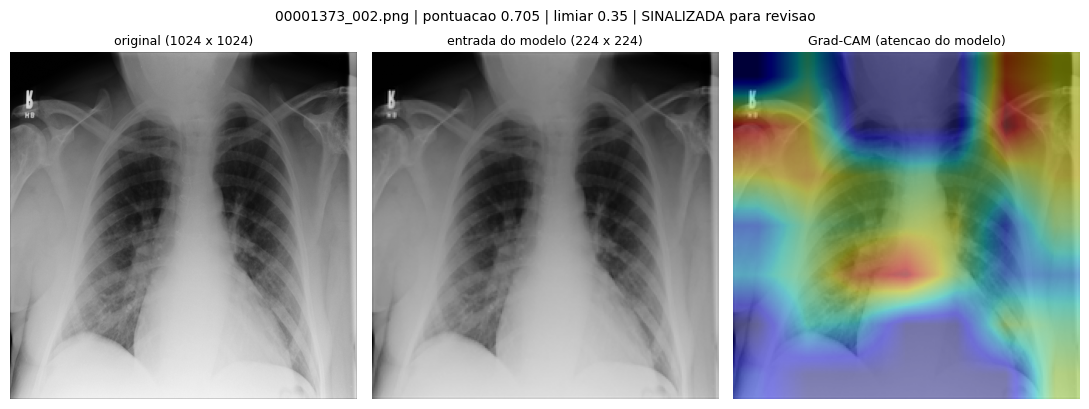

Pontuacao do modelo: 0.705 (escala de 0 a 1, nao calibrada: nao e uma probabilidade de doenca)
Limiar: 0.35
Resultado: SINALIZADA para revisao. A pontuacao esta acima do limiar.
Laudo de referencia (rotulo do NIH, nao validado clinicamente): cardiomegalia
Comparacao: coincide com o laudo.
Contexto: No conjunto de teste, com este limiar, o modelo sinalizou 17 dos 19 casos com cardiomegalia no laudo, mas tambem sinalizou 140 das 427 imagens sem achados. Precisao: 11% (a maior parte das sinalizacoes nao tinha cardiomegalia no laudo). Teste com apenas 19 positivos: estimativa incerta.
Projeto academico. Nao e diagnostico e nao deve apoiar decisao clinica.
Exemplo 2: 00017618_019.png


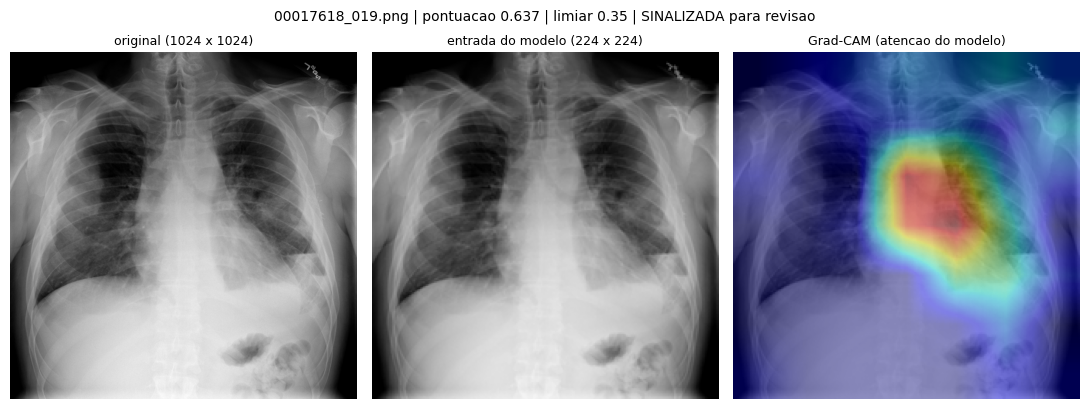

Pontuacao do modelo: 0.637 (escala de 0 a 1, nao calibrada: nao e uma probabilidade de doenca)
Limiar: 0.35
Resultado: SINALIZADA para revisao. A pontuacao esta acima do limiar.
Laudo de referencia (rotulo do NIH, nao validado clinicamente): cardiomegalia
Comparacao: coincide com o laudo.
Contexto: No conjunto de teste, com este limiar, o modelo sinalizou 17 dos 19 casos com cardiomegalia no laudo, mas tambem sinalizou 140 das 427 imagens sem achados. Precisao: 11% (a maior parte das sinalizacoes nao tinha cardiomegalia no laudo). Teste com apenas 19 positivos: estimativa incerta.
Projeto academico. Nao e diagnostico e nao deve apoiar decisao clinica.
Exemplo 3: 00017714_027.png


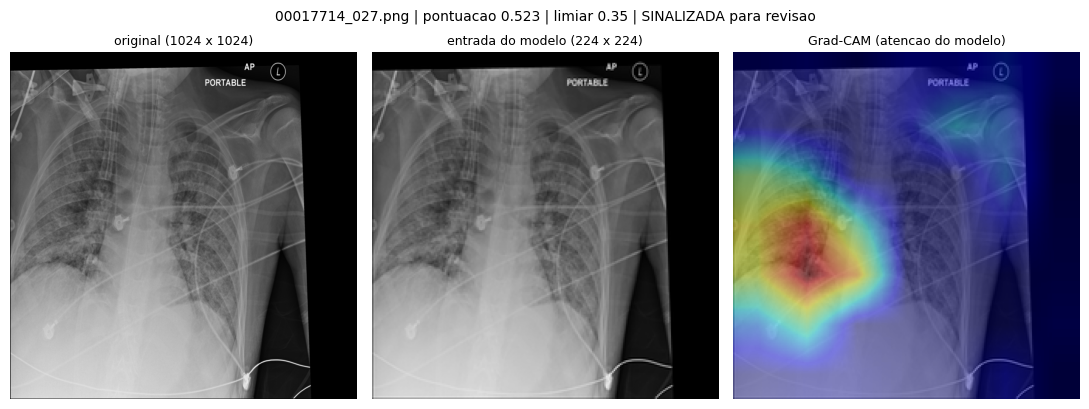

Pontuacao do modelo: 0.523 (escala de 0 a 1, nao calibrada: nao e uma probabilidade de doenca)
Limiar: 0.35
Resultado: SINALIZADA para revisao. A pontuacao esta acima do limiar.
Laudo de referencia (rotulo do NIH, nao validado clinicamente): sem achados
Comparacao: falso positivo.
Contexto: No conjunto de teste, com este limiar, o modelo sinalizou 17 dos 19 casos com cardiomegalia no laudo, mas tambem sinalizou 140 das 427 imagens sem achados. Precisao: 11% (a maior parte das sinalizacoes nao tinha cardiomegalia no laudo). Teste com apenas 19 positivos: estimativa incerta.
Projeto academico. Nao e diagnostico e nao deve apoiar decisao clinica.
Exemplo 4: 00011972_000.png


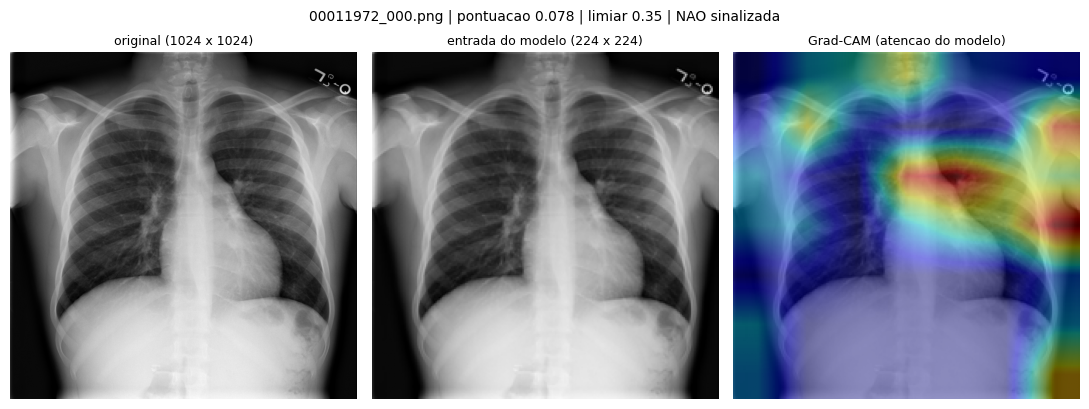

Pontuacao do modelo: 0.078 (escala de 0 a 1, nao calibrada: nao e uma probabilidade de doenca)
Limiar: 0.35
Resultado: NAO sinalizada. A pontuacao esta abaixo do limiar. Isso nao exclui cardiomegalia.
Laudo de referencia (rotulo do NIH, nao validado clinicamente): sem achados
Comparacao: coincide com o laudo.
Contexto: No conjunto de teste, com este limiar, o modelo sinalizou 17 dos 19 casos com cardiomegalia no laudo, mas tambem sinalizou 140 das 427 imagens sem achados. Precisao: 11% (a maior parte das sinalizacoes nao tinha cardiomegalia no laudo). Teste com apenas 19 positivos: estimativa incerta.
Projeto academico. Nao e diagnostico e nao deve apoiar decisao clinica.


In [8]:
rng = np.random.default_rng(SEED)
EXEMPLOS_SALVOS = []
if IMAGENS:
    for rotulo in [1, 1, 0, 0]:
        candidatos = [str(n) for n in nomes_teste if ROTULOS[str(n)] == rotulo and str(n) not in EXEMPLOS_SALVOS]
        EXEMPLOS_SALVOS.append(str(rng.choice(candidatos)))
    for k, nome in enumerate(EXEMPLOS_SALVOS, start=1):
        print("=" * 70)
        print("Exemplo %d: %s" % (k, nome))
        with Image.open(IMAGENS[nome]) as im:
            analisar(im.copy(), rotulo_referencia=ROTULOS[nome], titulo=nome, salvar=SAIDA / ("nb3_exemplo_%d.png" % k))
else:
    print("Dataset nao encontrado: exemplos nao gerados.")

In [9]:
# Reune os arquivos pequenos e baixa em um unico zip (Colab). Localmente, apenas informa a pasta.
pacote = SAIDA / "para_repositorio_nb3"
pacote.mkdir(exist_ok=True)
for nome in ["nb3_exemplo_1.png", "nb3_exemplo_2.png", "nb3_exemplo_3.png", "nb3_exemplo_4.png"]:
    if (SAIDA / nome).exists():
        shutil.copy(SAIDA / nome, pacote / nome)
(pacote / "exemplos_nb3.json").write_text(json.dumps({
    "semente": SEED, "modelo": "resnet50", "limiar": LIMIAR, "exemplos": EXEMPLOS_SALVOS,
    "rotulos_de_referencia": {n: int(ROTULOS[n]) for n in EXEMPLOS_SALVOS},
}, indent=2, ensure_ascii=False), encoding="utf-8")
if COLAB:
    from google.colab import files
    zip_path = shutil.make_archive("/content/pulso_f4_nb3_saidas", "zip", pacote)
    files.download(zip_path)
else:
    print("Arquivos para o repositorio em:", pacote)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Limitações do protótipo
- É uma demonstração acadêmica. Não passou por validação clínica nem regulatória.
- O modelo tem precisão baixa no teste: a maioria das imagens sinalizadas não tinha cardiomegalia no laudo. O resultado serve para ilustrar o fluxo, não para triagem.
- A pontuação não é calibrada e o limiar vem de uma validação com poucos positivos.
- O Grad-CAM mostra o que influenciou a pontuação do modelo. Ele pode destacar regiões sem relação com o coração e não substitui a leitura de um radiologista.
- O modelo foi treinado só com radiografias frontais do dataset NIH em 1024 x 1024. Imagens de outros equipamentos, projeções ou qualidade podem dar resultados sem sentido.
- Os rótulos de referência vêm de laudos do NIH, sem validação clínica independente.

O próximo passo é o Notebook 4, com a análise de fairness por sexo (Ir Além 1).